# Activity A – Image Reconstruction

In [63]:
!pip install -q "huggingface_hub==0.36.0" tf-keras safetensors

In [1]:
import huggingface_hub

print("Hugging Face Hub:", huggingface_hub.__version__)

from huggingface_hub import from_pretrained_keras
from huggingface_hub import PyTorchModelHubMixin

print("Keras loader imported successfully!")
print("PyTorch Hub mixin imported successfully!")

Hugging Face Hub: 0.36.0
Keras loader imported successfully!
PyTorch Hub mixin imported successfully!


In [2]:
AE_MODEL_ID = "keras-io/conv_autoencoder"

autoencoder = from_pretrained_keras(AE_MODEL_ID)

print("Pretrained Autoencoder Loaded Successfully!")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

logs/validation/events.out.tfevents.1654(…):   0%|          | 0.00/15.7k [00:00<?, ?B/s]

keras_metadata.pb:   0%|          | 0.00/19.7k [00:00<?, ?B/s]

saved_model.pb:   0%|          | 0.00/136k [00:00<?, ?B/s]

...

README.md: 0.00B [00:00, ?B/s]

variables.data-00000-of-00001:   0%|          | 0.00/119k [00:00<?, ?B/s]

model.png:   0%|          | 0.00/27.7k [00:00<?, ?B/s]

variables.index:   0%|          | 0.00/905 [00:00<?, ?B/s]

Pretrained Autoencoder Loaded Successfully!


In [3]:
!pip install -q \
    "huggingface_hub==0.36.0" \
    "transformers==4.48.3" \
    "tf-keras" \
    "safetensors"

In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tf_keras

import torch
import torch.nn as nn

from huggingface_hub import from_pretrained_keras
from transformers import AutoModel

print("TensorFlow:", tf.__version__)
print("PyTorch:", torch.__version__)

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Execution Device:", device)

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

TensorFlow: 2.21.0
PyTorch: 2.11.0+cu130
Execution Device: cuda


In [5]:
import huggingface_hub

print("Hugging Face Hub:", huggingface_hub.__version__)

from huggingface_hub import hf_hub_download

print("Hugging Face connection ready!")

Hugging Face Hub: 0.36.0
Hugging Face connection ready!


In [6]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize images
x_test = x_test.astype("float32") / 255.0

# Add channel dimension
x_test = np.expand_dims(x_test, axis=-1)

print("Testing Dataset:", x_test.shape)
print("Number of Testing Images:", len(x_test))
print("Training Images Used:", 0)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Testing Dataset: (10000, 28, 28, 1)
Number of Testing Images: 10000
Training Images Used: 0


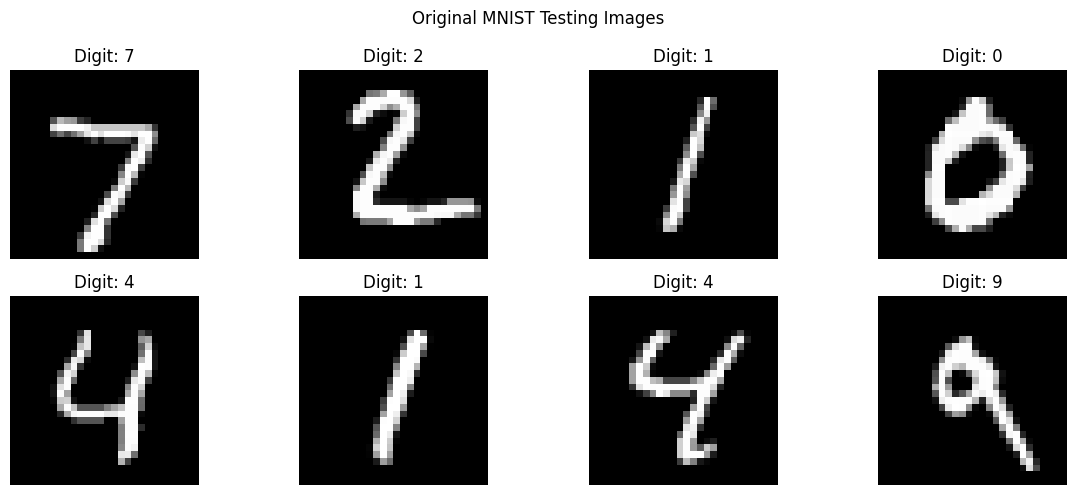

In [7]:
plt.figure(figsize=(12, 5))

for i in range(8):

    plt.subplot(2, 4, i + 1)

    plt.imshow(x_test[i].squeeze(), cmap="gray")

    plt.title(f"Digit: {y_test[i]}")

    plt.axis("off")

plt.suptitle("Original MNIST Testing Images")

plt.tight_layout()
plt.show()

In [8]:
AE_MODEL_ID = "keras-io/conv_autoencoder"

autoencoder = from_pretrained_keras(AE_MODEL_ID)

print("Pretrained Autoencoder Loaded Successfully!")

print("Model:", AE_MODEL_ID)

print("Training Required: No")

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Pretrained Autoencoder Loaded Successfully!
Model: keras-io/conv_autoencoder
Training Required: No


In [9]:
np.random.seed(42)

# Select 8 testing images
original_images = x_test[:8]

# Add Gaussian noise
noise_factor = 0.5

noisy_images = original_images + noise_factor * np.random.normal(
    loc=0.0,
    scale=1.0,
    size=original_images.shape
)

noisy_images = np.clip(noisy_images, 0.0, 1.0)

print("Original Shape:", original_images.shape)
print("Noisy Shape:", noisy_images.shape)

Original Shape: (8, 28, 28, 1)
Noisy Shape: (8, 28, 28, 1)


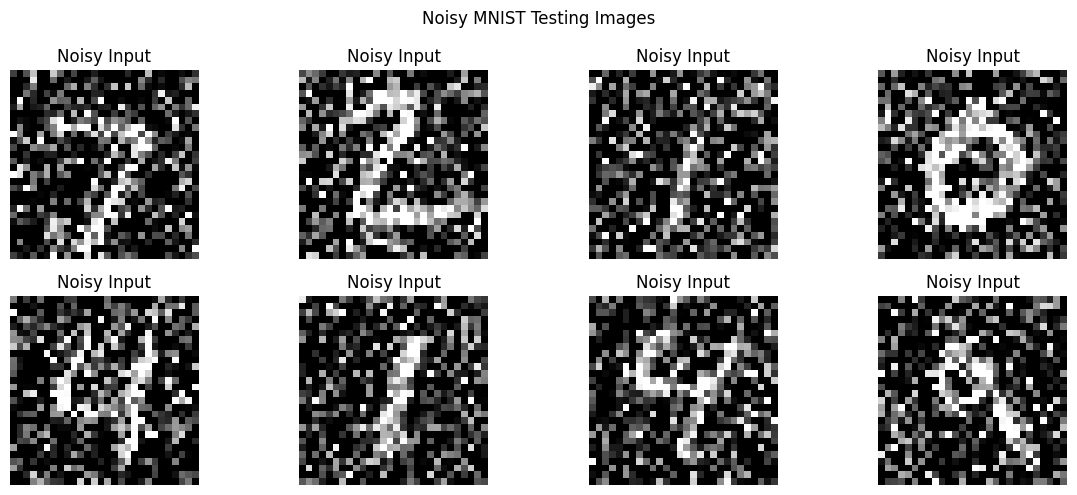

In [10]:
plt.figure(figsize=(12, 5))

for i in range(8):

    plt.subplot(2, 4, i + 1)

    plt.imshow(noisy_images[i].squeeze(), cmap="gray")

    plt.title("Noisy Input")

    plt.axis("off")

plt.suptitle("Noisy MNIST Testing Images")

plt.tight_layout()
plt.show()

In [11]:
ae_reconstructed = autoencoder.predict(
    noisy_images,
    verbose=0
)

print("Autoencoder Reconstruction Completed!")

print("Input Shape:", noisy_images.shape)

print("Output Shape:", ae_reconstructed.shape)

Autoencoder Reconstruction Completed!
Input Shape: (8, 28, 28, 1)
Output Shape: (8, 28, 28, 1)


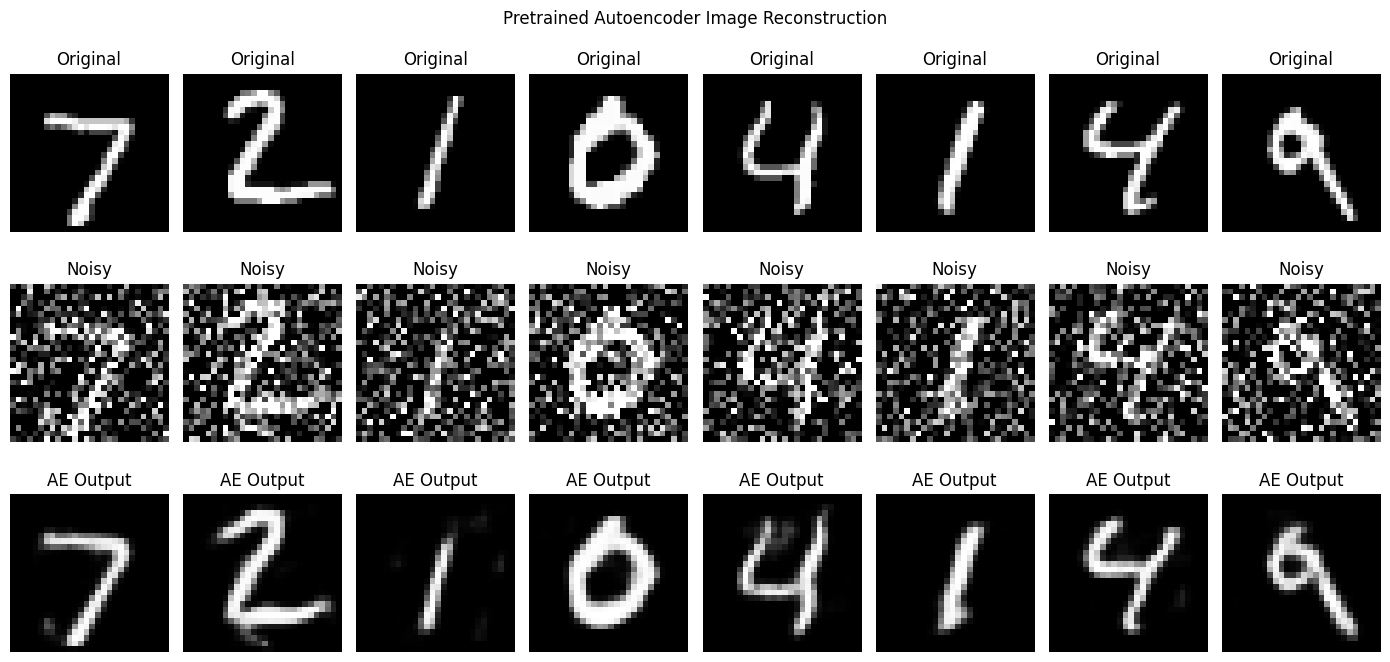

In [12]:
plt.figure(figsize=(14, 7))

for i in range(8):

    # Original
    plt.subplot(3, 8, i + 1)

    plt.imshow(original_images[i].squeeze(), cmap="gray")

    plt.title("Original")

    plt.axis("off")

    # Noisy
    plt.subplot(3, 8, i + 9)

    plt.imshow(noisy_images[i].squeeze(), cmap="gray")

    plt.title("Noisy")

    plt.axis("off")

    # Reconstructed
    plt.subplot(3, 8, i + 17)

    plt.imshow(ae_reconstructed[i].squeeze(), cmap="gray")

    plt.title("AE Output")

    plt.axis("off")

plt.suptitle("Pretrained Autoencoder Image Reconstruction")

plt.tight_layout()
plt.show()

## Pretrained Variational Autoencoder

In [13]:
VAE_MODEL_ID = "uday9k/Binarized_MNIST_VAE"

vae = AutoModel.from_pretrained(
    VAE_MODEL_ID,
    trust_remote_code=True
)

vae = vae.to(device)

vae.eval()

print("Pretrained VAE Loaded Successfully!")

print("Model:", VAE_MODEL_ID)

print("Training Required: No")

config.json:   0%|          | 0.00/710 [00:00<?, ?B/s]

configuration_vae.py:   0%|          | 0.00/615 [00:00<?, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/uday9k/Binarized_MNIST_VAE:
- configuration_vae.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


modeling_vae.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/uday9k/Binarized_MNIST_VAE:
- modeling_vae.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


customVAE_model2.pth:   0%|          | 0.00/36.8M [00:00<?, ?B/s]

Pretrained VAE Loaded Successfully!
Model: uday9k/Binarized_MNIST_VAE
Training Required: No


In [14]:
# Select the same 8 original testing images

vae_images = original_images.copy()

# Binarize images
vae_images = (vae_images > 0.5).astype("float32")

# Convert to PyTorch tensor
vae_inputs = torch.tensor(
    vae_images
).permute(0, 3, 1, 2).to(device)

print("VAE Input Shape:", vae_inputs.shape)

VAE Input Shape: torch.Size([8, 1, 28, 28])


In [15]:
with torch.no_grad():

    # Encode input
    mu, logvar = vae.encode(
        vae_inputs.reshape(vae_inputs.shape[0], -1)
    )

    # Use mean instead of random sampling
    latent = mu

    # Decode latent representation
    vae_reconstructed, _ = vae.decode(latent)

    # Reshape output
    vae_reconstructed = vae_reconstructed.reshape(
        -1, 1, 28, 28
    )

print("VAE Reconstruction Completed!")

print("Input Shape:", vae_inputs.shape)

print("Output Shape:", vae_reconstructed.shape)

VAE Reconstruction Completed!
Input Shape: torch.Size([8, 1, 28, 28])
Output Shape: torch.Size([8, 1, 28, 28])


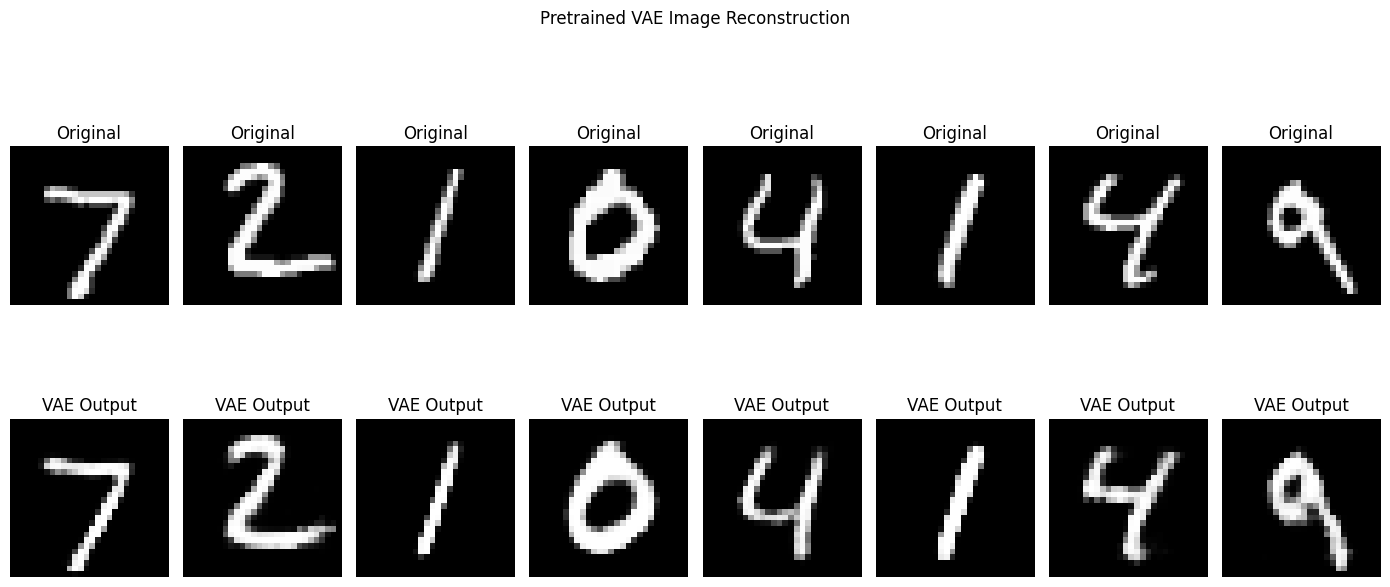

In [16]:
vae_outputs = (
    vae_reconstructed
    .cpu()
    .numpy()
)

plt.figure(figsize=(14, 7))

for i in range(8):

    # Original
    plt.subplot(2, 8, i + 1)

    plt.imshow(original_images[i].squeeze(), cmap="gray")

    plt.title("Original")

    plt.axis("off")

    # Reconstructed
    plt.subplot(2, 8, i + 9)

    plt.imshow(vae_outputs[i].squeeze(), cmap="gray")

    plt.title("VAE Output")

    plt.axis("off")

plt.suptitle("Pretrained VAE Image Reconstruction")

plt.tight_layout()
plt.show()

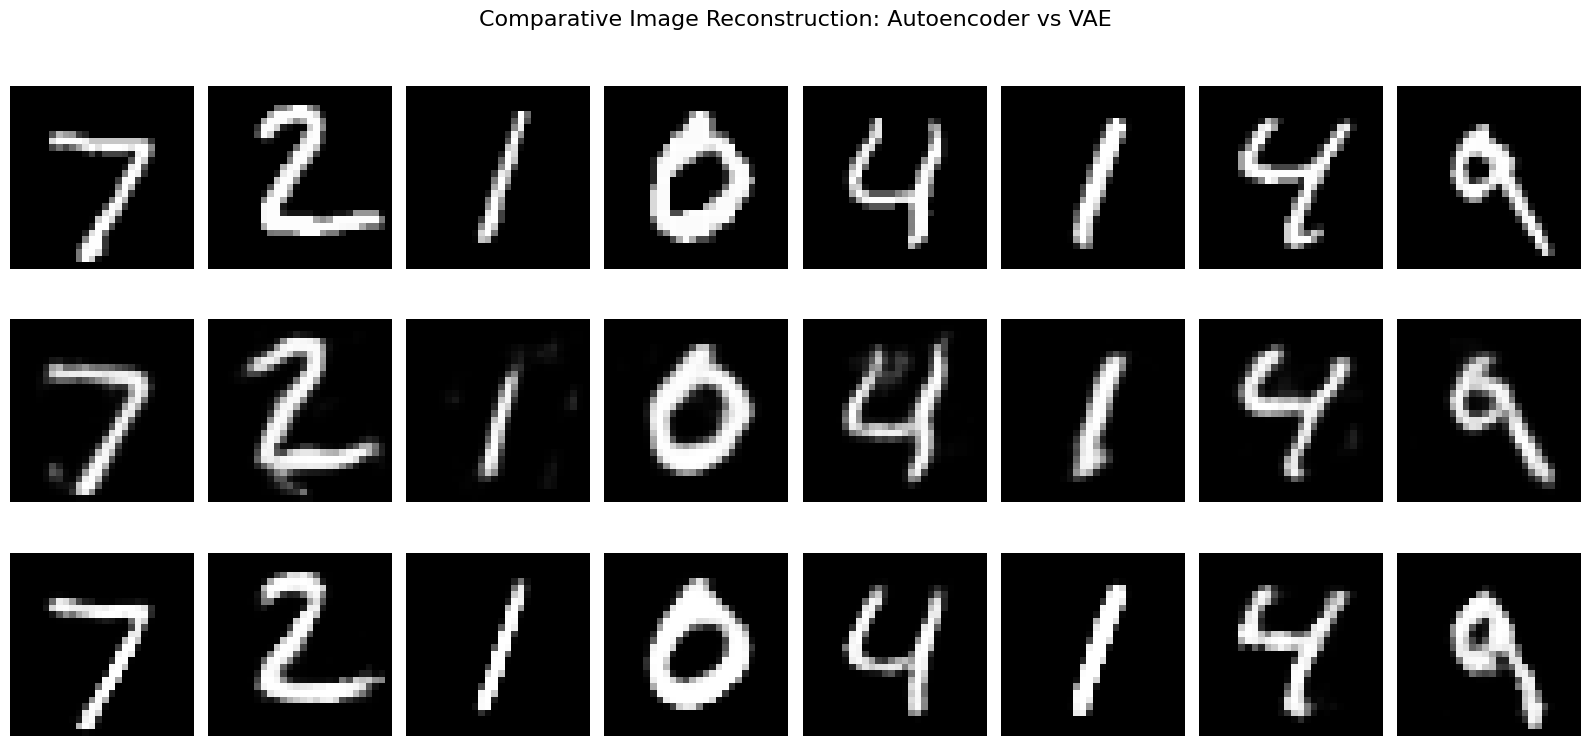

In [17]:
fig, axes = plt.subplots(3, 8, figsize=(16, 8))

for i in range(8):

    # Original
    axes[0, i].imshow(
        original_images[i].squeeze(),
        cmap="gray"
    )

    axes[0, i].axis("off")

    # Autoencoder
    axes[1, i].imshow(
        ae_reconstructed[i].squeeze(),
        cmap="gray"
    )

    axes[1, i].axis("off")

    # VAE
    axes[2, i].imshow(
        vae_outputs[i].squeeze(),
        cmap="gray"
    )

    axes[2, i].axis("off")


axes[0, 0].set_ylabel("Original", fontsize=12)

axes[1, 0].set_ylabel("Autoencoder", fontsize=12)

axes[2, 0].set_ylabel("VAE", fontsize=12)


plt.suptitle(
    "Comparative Image Reconstruction: Autoencoder vs VAE",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "/content/AE_VAE_Final_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
print("=" * 50)

print("IMAGE RECONSTRUCTION EXPERIMENT")

print("=" * 50)

print("\nMODEL 1: AUTOENCODER")

print("Model:", AE_MODEL_ID)

print("Dataset: MNIST")

print("Input: Noisy Testing Images")

print("Training: Not Performed")

# print("MSE:", ae_mse)


print("\nMODEL 2: VARIATIONAL AUTOENCODER")

print("Model:", VAE_MODEL_ID)

print("Dataset: MNIST")

print("Input: Binarized Testing Images")

print("Training: Not Performed")

# print("MSE:", vae_mse)


print("\nEXPERIMENT COMPLETED!")

IMAGE RECONSTRUCTION EXPERIMENT

MODEL 1: AUTOENCODER
Model: keras-io/conv_autoencoder
Dataset: MNIST
Input: Noisy Testing Images
Training: Not Performed

MODEL 2: VARIATIONAL AUTOENCODER
Model: uday9k/Binarized_MNIST_VAE
Dataset: MNIST
Input: Binarized Testing Images
Training: Not Performed

EXPERIMENT COMPLETED!


# Activity B – Image Generation

Practical - Image Generation using DCGAN and Diffusion Model

In [36]:
!git clone https://github.com/shivamswarnkar/Image-Generator.git

%cd Image-Generator

fatal: destination path 'Image-Generator' already exists and is not an empty directory.
/content/Image-Generator


In [37]:
!pip install -q torch torchvision matplotlib pillow

In [38]:
import os

pretrained_path = "pretrained_models"

print("Available pretrained models:")

for root, dirs, files in os.walk(pretrained_path):
    for file in files:
        print(os.path.join(root, file))

Available pretrained models:
pretrained_models/landmark_netG.pth
pretrained_models/celeba_netD.pth
pretrained_models/landmark_netD.pth
pretrained_models/flowers_netD.pth
pretrained_models/celeba_netG.pth
pretrained_models/flowers_netG.pth


## DCGAN

In [41]:
import os

print("Current Directory:", os.getcwd())

os.makedirs("output", exist_ok=True)

print("Output folder ready!")

Current Directory: /content/Image-Generator
Output folder ready!


In [42]:
!python generate.py \
    --netG pretrained_models/celeba_netG.pth \
    --n 4 \
    --output_path output/dcgan_four_faces.png

In [43]:
import os

output_path = "output/dcgan_four_faces.png"

if os.path.exists(output_path):
    print("Image generated successfully!")
    print("File size:", os.path.getsize(output_path), "bytes")
else:
    print("Image not found. Check the generation cell output.")
    print("Available output files:", os.listdir("output"))

Image generated successfully!
File size: 106188 bytes


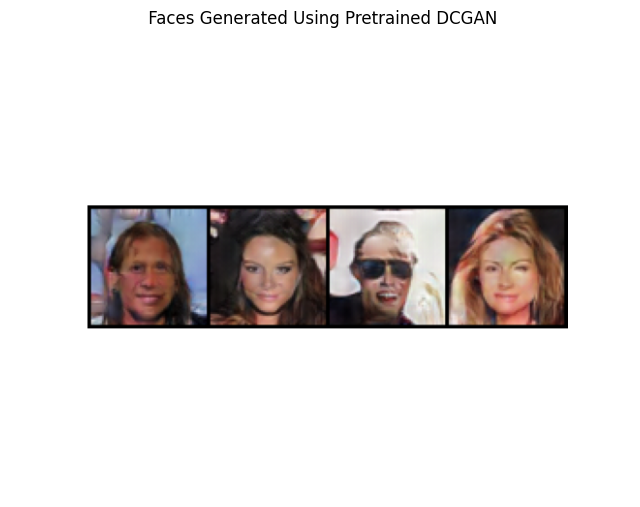

In [52]:
from PIL import Image
import matplotlib.pyplot as plt

dcgan_image = Image.open(output_path)

plt.figure(figsize=(8, 8))
plt.imshow(dcgan_image)
plt.title(" Faces Generated Using Pretrained DCGAN")
plt.axis("off")
plt.show()

In [51]:
dcgan_image.save("/content/DCGAN_Generated.png")

print("DCGAN images saved successfully!")

DCGAN images saved successfully!


In [32]:
!python generate.py --netG pretrained_models/celeba_netG.pth --n 4

python3: can't open file '/content/generate.py': [Errno 2] No such file or directory


## PART B – IMAGE GENERATION USING STABLE DIFFUSION

In [9]:
%cd /content

!pip install -q diffusers transformers accelerate safetensors

/content


In [10]:
import torch
import matplotlib.pyplot as plt

from diffusers import StableDiffusionPipeline

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Execution Device:", device)

Execution Device: cuda


In [11]:
MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"

dtype = torch.float16 if device == "cuda" else torch.float32

pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=dtype,
    use_safetensors=True
)

pipe = pipe.to(device)

print("Stable Diffusion Loaded Successfully!")
print("Model:", MODEL_ID)
print("Training Required: No")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Stable Diffusion Loaded Successfully!
Model: stable-diffusion-v1-5/stable-diffusion-v1-5
Training Required: No


In [25]:
prompts = [
    """
      A photorealistic celebrity portrait photograph,
    close-up headshot of a famous Hollywood movie star,
    looking directly at the camera, realistic human face,
    natural skin texture, detailed eyes, realistic hair,
    studio portrait photography, neutral background,
    professional lighting, high resolution,
    centered face, front-facing portrait
    """
]

negative_prompt = """
cartoon, anime, painting, illustration,
blurry, distorted face, asymmetrical eyes,
deformed facial features, extra eyes,
extra ears, bad anatomy, low quality,
unnatural skin, duplicate face
"""

In [27]:
import torch

generated_images = []

for i in range(4):

    generator = torch.Generator(device=device).manual_seed(100 + i)

    result = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        num_inference_steps=30,
        guidance_scale=7.5,
        generator=generator
    )

    generated_images.append(result.images[0])

    print(f"Generated image {i+1}/4")

  0%|          | 0/30 [00:00<?, ?it/s]

Generated image 1/4


  0%|          | 0/30 [00:00<?, ?it/s]

Generated image 2/4


  0%|          | 0/30 [00:00<?, ?it/s]

Generated image 3/4


  0%|          | 0/30 [00:00<?, ?it/s]

Generated image 4/4


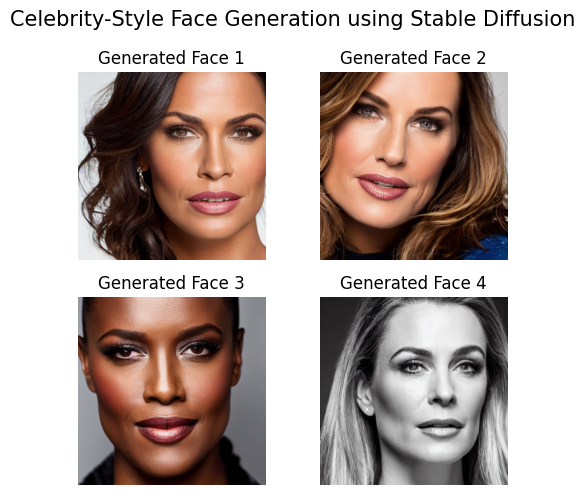

In [53]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(5, 5))

for i, image in enumerate(generated_images):

    row = i // 2
    col = i % 2

    axes[row, col].imshow(image)
    axes[row, col].set_title(f"Generated Face {i+1}")
    axes[row, col].axis("off")

plt.suptitle(
    "Celebrity-Style Face Generation using Stable Diffusion",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "/content/Stable_Diffusion_4_Faces.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [54]:
for i, image in enumerate(generated_images):

    image.save(f"/content/Diffusion_Image_{i+1}.png")

print("All Stable Diffusion images saved successfully!")

All Stable Diffusion images saved successfully!


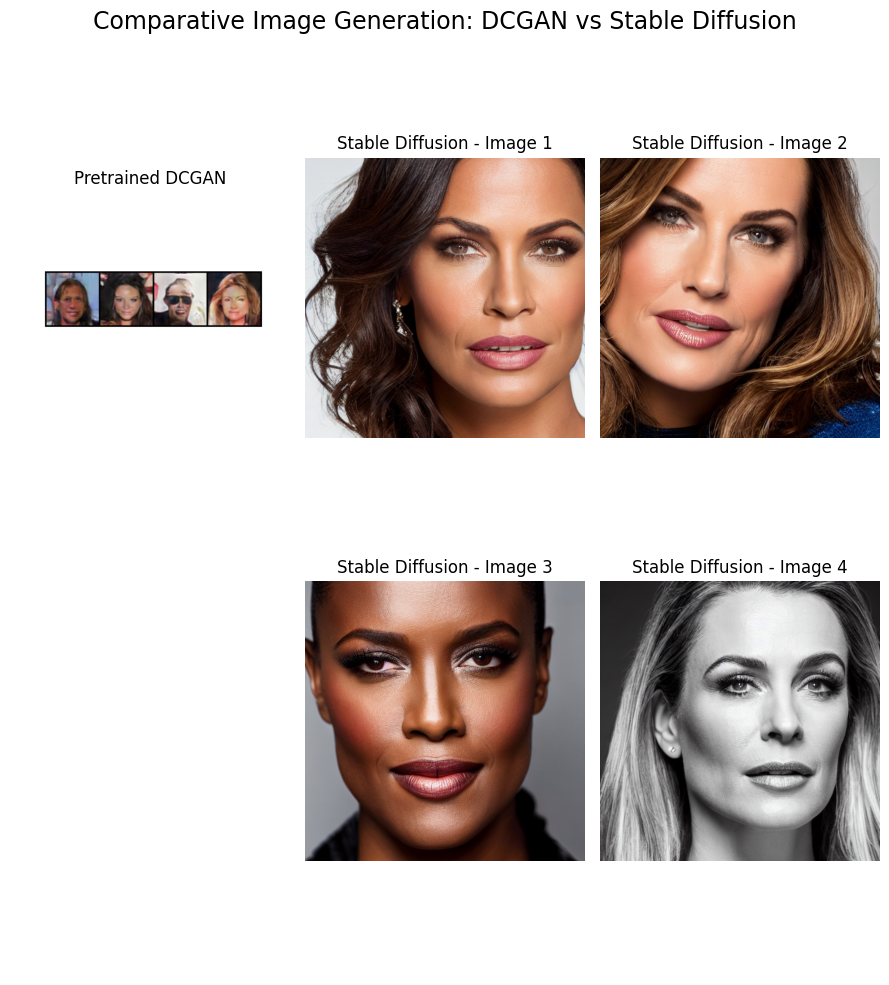

In [58]:
import matplotlib.pyplot as plt
from PIL import Image

# Load DCGAN generated images
dcgan_output = Image.open("/content/DCGAN_Generated.png")

# Create diffusion image grid
fig, axes = plt.subplots(2, 3, figsize=(9, 10))

# DCGAN output
axes[0, 0].imshow(dcgan_output)
axes[0, 0].set_title("Pretrained DCGAN")
axes[0, 0].axis("off")

# Stable Diffusion outputs
for i, image in enumerate(generated_images):

    row = (i // 2)
    col = (i % 2) + 1

    axes[row, col].imshow(image)
    axes[row, col].set_title(f"Stable Diffusion - Image {i+1}")
    axes[row, col].axis("off")

# Empty bottom-left position
axes[1, 0].axis("off")

plt.suptitle(
    "Comparative Image Generation: DCGAN vs Stable Diffusion",
    fontsize=17
)

plt.tight_layout()

plt.savefig(
    "/content/Final_Generation_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [49]:
print("IMAGE GENERATION EXPERIMENT")
print("=" * 45)

print("\nMODEL 1: DCGAN")
print("Dataset: CelebA")
print("Checkpoint: celeba_netG.pth")
print("Generation Method: Random Noise")
print("Images Generated: 64")
print("Training: Not Performed")

print("\nMODEL 2: STABLE DIFFUSION")
print("Model: Stable Diffusion 1.5")
print("Source: Hugging Face")
print("Generation Method: Text-to-Image")
print("Images Generated:", len(generated_images))
print("Training: Not Performed")

print("\nFINAL OUTPUTS")
print("DCGAN: /content/DCGAN_Generated.png")
print("Comparison: /content/Final_Generation_Comparison.png")

print("\nExperiment Completed Successfully!")

IMAGE GENERATION EXPERIMENT

MODEL 1: DCGAN
Dataset: CelebA
Checkpoint: celeba_netG.pth
Generation Method: Random Noise
Images Generated: 64
Training: Not Performed

MODEL 2: STABLE DIFFUSION
Model: Stable Diffusion 1.5
Source: Hugging Face
Generation Method: Text-to-Image
Images Generated: 4
Training: Not Performed

FINAL OUTPUTS
DCGAN: /content/DCGAN_Generated.png
Comparison: /content/Final_Generation_Comparison.png

Experiment Completed Successfully!
